# Credit Card Fraud Detection

**Goal:** detect fraudulent credit-card transactions (`Class` = 1) among hundreds of thousands of normal ones.

**Dataset:** `creditcard.csv` - 284,807 European card transactions over two days. Features `V1`-`V28` are anonymised (PCA-transformed) numbers, plus `Time` (seconds since the first transaction), `Amount` and the label `Class`.

**The core difficulty is class imbalance:** only about 0.17% of transactions are fraud. A model that always says "legitimate" would be 99.8% accurate and completely useless, so **accuracy is the wrong metric**. We use precision, recall, F1 and especially the **area under the precision-recall curve (PR-AUC)**.

**Plan**
1. Load data, check quality, remove duplicates
2. Exploratory analysis
3. Prepare features and split into train / validation / test (stratified)
4. Try several ways of handling imbalance: none, class weights, undersampling, SMOTE (own implementation), and tree models
5. Pick the model and the decision threshold on the **validation** set
6. Report final results once on the untouched **test** set, plus a business-cost view

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score, roc_auc_score,
                             matthews_corrcoef, precision_recall_curve, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

sns.set_theme(style='whitegrid', palette='deep')
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## 1. Load data and check quality

In [2]:
df = pd.read_csv('data/creditcard.csv')
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()), '| of which fraud:', int(df[df.duplicated()]['Class'].sum()))
df.head()

Shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081 | of which fraud: 19

   Time        V1        V2        V3        V4        V5        V6        V7        V8        V9       V10       V11       V12       V13       V14       V15       V16       V17       V18       V19  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599  0.098698  0.363787  0.090794 -0.551600 -0.617801 -0.991390 -0.311169  1.468177 -0.470401  0.207971  0.025791  0.403993   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803  0.085102 -0.255425 -0.166974  1.612727  1.065235  0.489095 -0.143772  0.635558  0.463917 -0.114805 -0.183361 -0.145783   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461  0.247676 -1.514654  0.207643  0.624501  0.066084  0.717293 -0.165946  2.345865 -2.890083  1.109969 -0.121359 -2.261857   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609  0.377436 -1.387024 -0.054952 -0.226487  0.178228  0.507757 -0.287924 -0.631418 -1.059647 -0.684093  1.965775 -1.23262

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
counts = df['Class'].value_counts()
print('After removing duplicates:', df.shape)
print(f'Legitimate: {counts[0]:,}   Fraud: {counts[1]:,}   Fraud rate: {counts[1] / len(df):.3%}   (1 fraud per {counts[0] / counts[1]:.0f} normal)')

After removing duplicates: (283726, 31)
Legitimate: 283,253   Fraud: 473   Fraud rate: 0.167%   (1 fraud per 599 normal)

In [4]:
# What accuracy would a model that never flags fraud get?
dummy = DummyClassifier(strategy='most_frequent').fit(df[['Amount']], df['Class'])
print(f"Always predict 'legitimate': accuracy = {dummy.score(df[['Amount']], df['Class']):.4%}, fraud caught = 0")

Always predict 'legitimate': accuracy = 99.8333%, fraud caught = 0

## 2. Exploratory data analysis

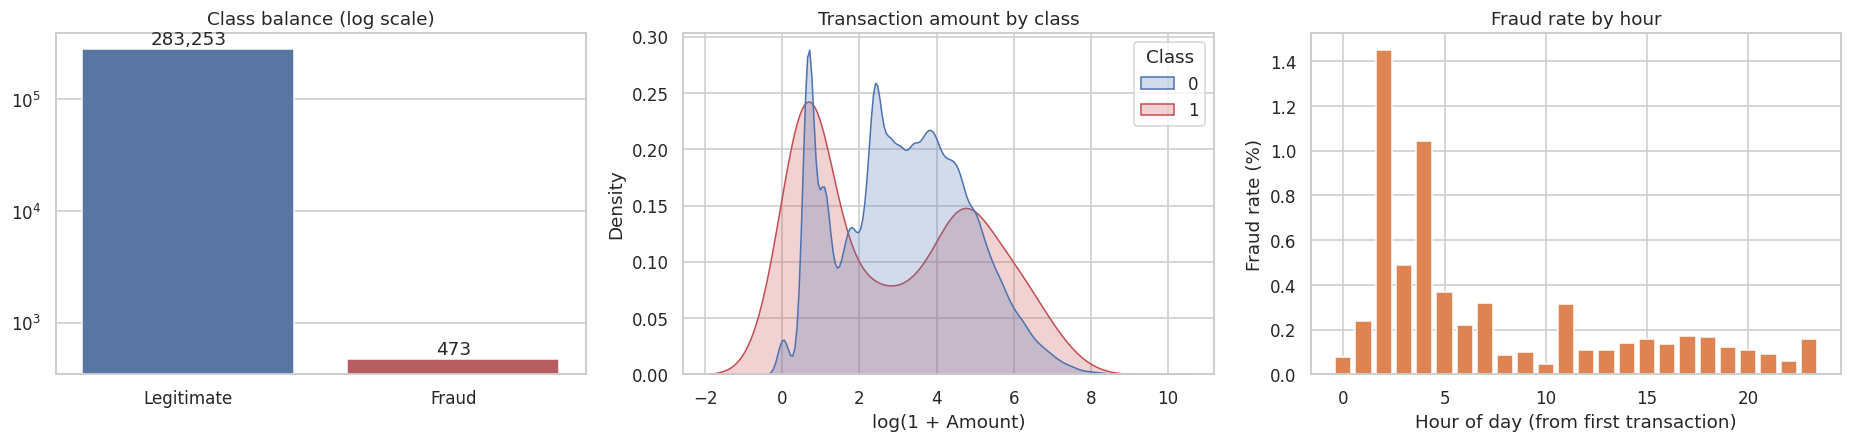

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.barplot(x=['Legitimate', 'Fraud'], y=counts.values, ax=axes[0], palette=['#4C72B0', '#C44E52'])
axes[0].set_yscale('log'); axes[0].set_title('Class balance (log scale)')
for i, v in enumerate(counts.values):
    axes[0].text(i, v * 1.1, f'{v:,}', ha='center')

sns.kdeplot(data=df, x=np.log1p(df['Amount']), hue='Class', common_norm=False, fill=True, ax=axes[1], palette=['#4C72B0', '#C44E52'])
axes[1].set_xlabel('log(1 + Amount)'); axes[1].set_title('Transaction amount by class')

hour = (df['Time'] // 3600) % 24
rate = df.groupby(hour)['Class'].mean() * 100
axes[2].bar(rate.index, rate.values, color='#DD8452')
axes[2].set_xlabel('Hour of day (from first transaction)'); axes[2].set_ylabel('Fraud rate (%)'); axes[2].set_title('Fraud rate by hour')
plt.tight_layout()

In [6]:
summary = df.groupby('Class')['Amount'].describe()[['count', 'mean', '50%', 'max']].round(2)
summary.index = ['Legitimate', 'Fraud']
summary

               count    mean    50%       max
Legitimate  283253.0   88.41  22.00  25691.16
Fraud          473.0  123.87   9.82   2125.87

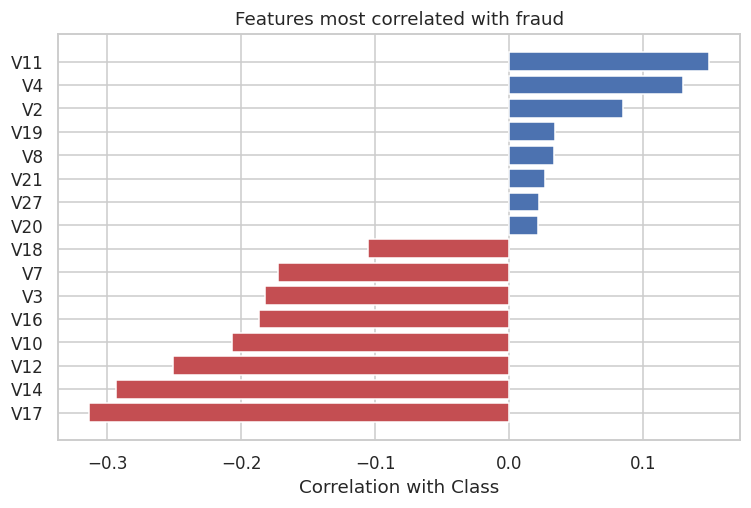

In [7]:
corr = df.drop(columns=['Time']).corr()['Class'].drop('Class').sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])
plt.figure(figsize=(8, 4.8))
plt.barh(top.index, top.values, color=['#C44E52' if v < 0 else '#4C72B0' for v in top.values])
plt.xlabel('Correlation with Class'); plt.title('Features most correlated with fraud')

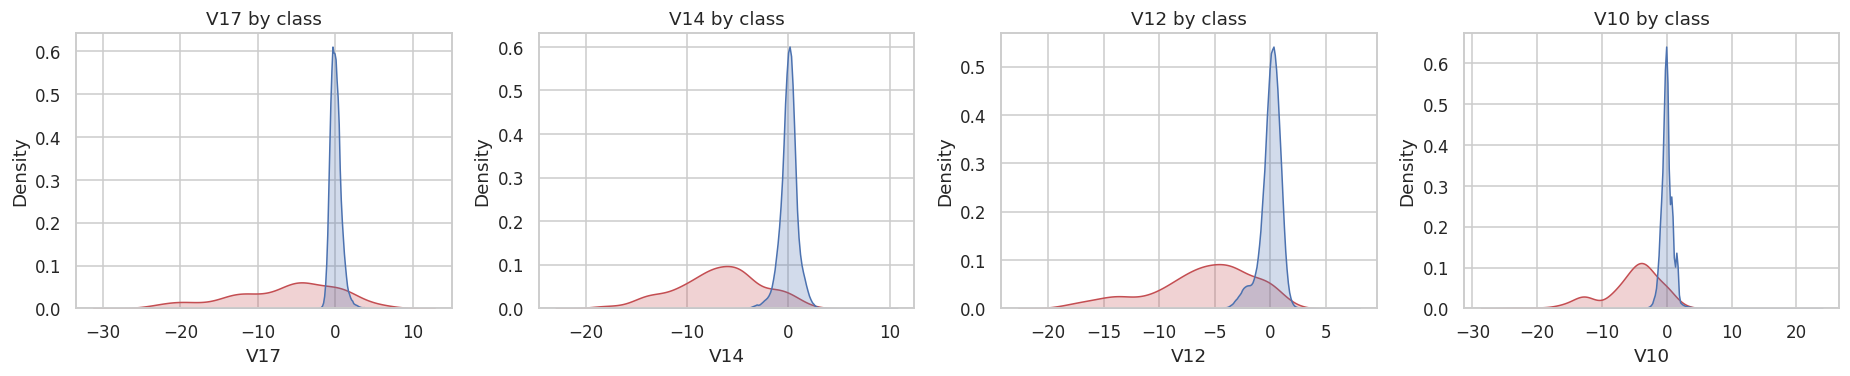

In [8]:
best_feats = corr.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, f in zip(axes, best_feats):
    sns.kdeplot(data=df, x=f, hue='Class', common_norm=False, fill=True, ax=ax, palette=['#4C72B0', '#C44E52'], legend=False)
    ax.set_title(f'{f} by class')
plt.tight_layout()

**Observations**
- Fraud is extremely rare: 473 frauds against 283,253 legitimate transactions (1 in about 600) after removing 1,081 duplicate rows.
- Fraudulent transactions are **typically small**: the median fraud is about $10 versus $22 for a legitimate transaction, and 36% of frauds are $1 or less (only 11% of legitimate ones). This looks like "card testing" with tiny amounts. A few large frauds (up to about $2,100) pull the fraud *average* above the legitimate average.
- The fraud rate is far higher in the early-morning hours of the data (hours 2 and 4 show about 1.5% and 1.0% versus 0.17% overall), although fewer transactions happen then.
- The anonymised features most negatively correlated with fraud are **V17, V14, V12, V10 and V16**; the most positive are V11 and V4. These are the same features the models rely on most (section 7).
- Fraud and legitimate transactions overlap heavily in any single feature, so a model has to combine many of them.

## 3. Prepare features and split the data

- `Amount` is heavily skewed, so we use `log(1 + Amount)`.
- `Time` is seconds since the first transaction, which is not meaningful on its own; the **hour of day** is more useful.
- The data is split **stratified** into 60% train / 20% validation / 20% test so each part has the same small fraud share. Models are fitted on train, compared and tuned on validation, and the test set is used **once** at the end.

In [9]:
data = df.copy()
data['Amount_log'] = np.log1p(data['Amount'])
data['Hour'] = (data['Time'] // 3600) % 24
feature_cols = [f'V{i}' for i in range(1, 29)] + ['Amount_log', 'Hour']

X = data[feature_cols].values
y = data['Class'].values
amount = data['Amount'].values

idx = np.arange(len(data))
i_trainval, i_test = train_test_split(idx, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
i_train, i_val = train_test_split(i_trainval, test_size=0.25, stratify=y[i_trainval], random_state=RANDOM_STATE)
X_train, y_train = X[i_train], y[i_train]
X_val, y_val = X[i_val], y[i_val]
X_test, y_test = X[i_test], y[i_test]

pd.DataFrame({'rows': [len(y_train), len(y_val), len(y_test)], 'frauds': [y_train.sum(), y_val.sum(), y_test.sum()],
              'fraud rate %': [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100]},
             index=['train', 'validation', 'test']).round(3)

              rows  frauds  fraud rate %
train       170235     284         0.167
validation   56745      94         0.166
test         56746      95         0.167

## 4. Handling the imbalance

All resampling is applied to the **training set only** - never to validation or test data, which must keep the real-world fraud rate.

Techniques compared (with logistic regression as a fast, simple base model):
1. **Nothing** - baseline
2. **Class weights** - make a missed fraud cost more during training
3. **Random undersampling** - keep all frauds but only 10 legitimate rows per fraud
4. **SMOTE** - create synthetic frauds by interpolating between real neighbouring frauds (implemented here with scikit-learn's nearest neighbours)

Then stronger non-linear models: **Random Forest** and **Gradient Boosting**.

In [10]:
def undersample(X, y, ratio=10, seed=RANDOM_STATE):
    """Keep every fraud and `ratio` legitimate rows per fraud."""
    r = np.random.default_rng(seed)
    fraud = np.where(y == 1)[0]
    legit = r.choice(np.where(y == 0)[0], size=ratio * len(fraud), replace=False)
    keep = np.concatenate([fraud, legit])
    return X[keep], y[keep]

def smote(X, y, ratio=0.1, k=5, seed=RANDOM_STATE):
    """Add synthetic fraud rows until fraud:legit = ratio (default 1:10)."""
    r = np.random.default_rng(seed)
    Xm = X[y == 1]
    n_new = max(0, int(ratio * (y == 0).sum()) - len(Xm))
    neighbours = NearestNeighbors(n_neighbors=k + 1).fit(Xm).kneighbors(Xm, return_distance=False)[:, 1:]
    base = r.integers(0, len(Xm), n_new)
    partner = neighbours[base, r.integers(0, k, n_new)]
    synthetic = Xm[base] + r.random((n_new, 1)) * (Xm[partner] - Xm[base])
    return np.vstack([X, synthetic]), np.concatenate([y, np.ones(n_new, dtype=int)])

Xu, yu = undersample(X_train, y_train)
Xs, ys = smote(X_train, y_train)
print('Undersampled training set:', Xu.shape, 'fraud share', round(yu.mean(), 3))
print('SMOTE training set       :', Xs.shape, 'fraud share', round(ys.mean(), 3))

Undersampled training set: (3124, 30) fraud share 0.091
SMOTE training set       : (186946, 30) fraud share 0.091

In [11]:
def metrics(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {'Model': name, 'PR-AUC': average_precision_score(y_true, proba), 'ROC-AUC': roc_auc_score(y_true, proba),
            'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred), 'MCC': matthews_corrcoef(y_true, pred),
            'Frauds caught': int(((pred == 1) & (y_true == 1)).sum()), 'False alarms': int(((pred == 1) & (y_true == 0)).sum())}

lr = lambda **kw: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, **kw))
fitted, val_proba = {}, {}

fitted['LR - baseline'] = lr().fit(X_train, y_train)
fitted['LR - class weights'] = lr(class_weight='balanced').fit(X_train, y_train)
fitted['LR - undersampling'] = lr().fit(Xu, yu)
fitted['LR - SMOTE'] = lr().fit(Xs, ys)
for name, m in fitted.items():
    val_proba[name] = m.predict_proba(X_val)[:, 1]
pd.DataFrame([metrics(n, y_val, p) for n, p in val_proba.items()]).set_index('Model').round(3)

                    PR-AUC  ROC-AUC  Precision  Recall     F1    MCC  Frauds caught  False alarms
Model                                                                                            
LR - baseline        0.798    0.978      0.889   0.681  0.771  0.778             64             8
LR - class weights   0.790    0.983      0.052   0.915  0.099  0.215             86          1554
LR - undersampling   0.788    0.979      0.382   0.894  0.535  0.583             84           136
LR - SMOTE           0.800    0.980      0.420   0.894  0.571  0.612             84           116

Notice the trade-off at the default 0.5 threshold: class weights and resampling raise **recall** (more frauds caught) but create many **false alarms** (low precision). Each technique effectively shifts the model's probabilities; the threshold can be adjusted later, so **PR-AUC** (threshold-independent) is the fairer yardstick for comparing them.

In [12]:
import time
t0 = time.time()
fitted['Random Forest'] = RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=2, max_samples=0.3,
                                                 class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
print(f'Random Forest trained in {time.time() - t0:.0f}s')
t0 = time.time()
fitted['Gradient Boosting'] = HistGradientBoostingClassifier(max_iter=250, learning_rate=0.08, max_leaf_nodes=31,
                                                             l2_regularization=1.0, random_state=RANDOM_STATE).fit(X_train, y_train)
print(f'Gradient Boosting trained in {time.time() - t0:.0f}s')
for name in ['Random Forest', 'Gradient Boosting']:
    val_proba[name] = fitted[name].predict_proba(X_val)[:, 1]
val_table = pd.DataFrame([metrics(n, y_val, p) for n, p in val_proba.items()]).set_index('Model').sort_values('PR-AUC', ascending=False)
val_table.round(3)

Random Forest trained in 27s
Gradient Boosting trained in 2s

                    PR-AUC  ROC-AUC  Precision  Recall     F1    MCC  Frauds caught  False alarms
Model                                                                                            
Random Forest        0.862    0.954      0.904   0.798  0.847  0.849             75             8
Gradient Boosting    0.860    0.980      0.924   0.777  0.844  0.847             73             6
LR - SMOTE           0.800    0.980      0.420   0.894  0.571  0.612             84           116
LR - baseline        0.798    0.978      0.889   0.681  0.771  0.778             64             8
LR - class weights   0.790    0.983      0.052   0.915  0.099  0.215             86          1554
LR - undersampling   0.788    0.979      0.382   0.894  0.535  0.583             84           136

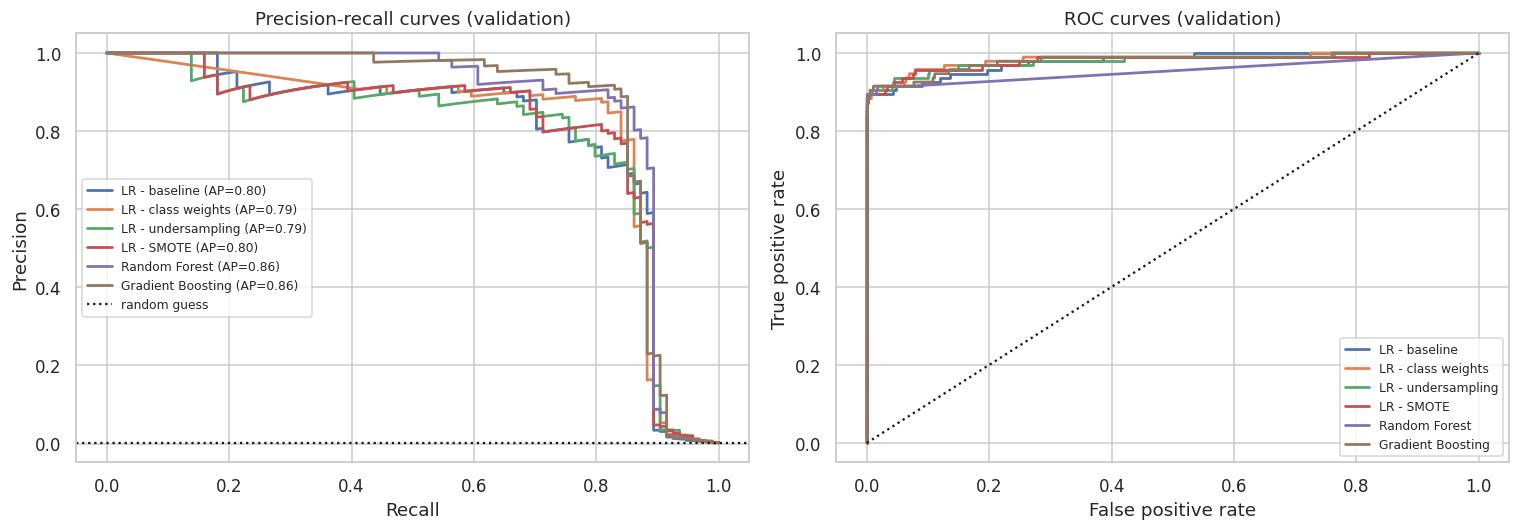

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, p in val_proba.items():
    pr, rc, _ = precision_recall_curve(y_val, p)
    axes[0].plot(rc, pr, label=f'{name} (AP={average_precision_score(y_val, p):.2f})', lw=1.8)
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[1].plot(fpr, tpr, label=name, lw=1.8)
axes[0].axhline(y_val.mean(), color='k', ls=':', label='random guess'); axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-recall curves (validation)'); axes[0].legend(fontsize=8)
axes[1].plot([0, 1], [0, 1], 'k:'); axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate')
axes[1].set_title('ROC curves (validation)'); axes[1].legend(fontsize=8)
plt.tight_layout()

On a highly imbalanced problem the ROC curve looks excellent for almost everything (the huge number of legitimate transactions makes the false-positive *rate* tiny), while the precision-recall curve separates the models clearly. That is why PR-AUC is the primary metric here.

## 5. Choose the model and the decision threshold (validation set)

The model with the best validation **PR-AUC** is selected. Then, instead of the default 0.5, we choose the probability threshold that maximises **F1** on the validation set - a balance between catching frauds (recall) and not annoying customers with false alarms (precision).

Selected model: Random Forest
Threshold chosen on validation (max F1): 0.233  (validation F1 = 0.862)

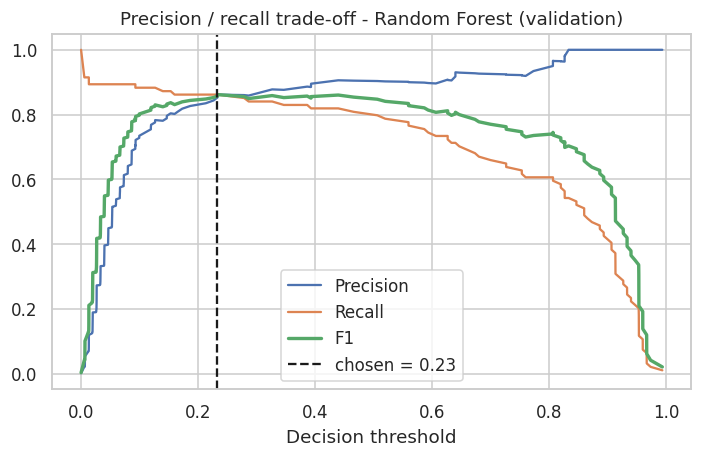

In [14]:
best_name = val_table['PR-AUC'].idxmax()
best_model = fitted[best_name]
pr, rc, th = precision_recall_curve(y_val, val_proba[best_name])
f1s = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-9, None)
threshold = float(th[f1s.argmax()])
print('Selected model:', best_name)
print(f'Threshold chosen on validation (max F1): {threshold:.3f}  (validation F1 = {f1s.max():.3f})')

plt.figure(figsize=(7.5, 4.2))
plt.plot(th, pr[:-1], label='Precision'); plt.plot(th, rc[:-1], label='Recall'); plt.plot(th, f1s, label='F1', lw=2.2)
plt.axvline(threshold, color='k', ls='--', label=f'chosen = {threshold:.2f}')
plt.xlabel('Decision threshold'); plt.title(f'Precision / recall trade-off - {best_name} (validation)'); plt.legend()

## 6. Final evaluation on the untouched test set

In [15]:
test_proba = best_model.predict_proba(X_test)[:, 1]
final = pd.DataFrame([metrics(f'{best_name} @ 0.5', y_test, test_proba, 0.5),
                      metrics(f'{best_name} @ {threshold:.2f} (tuned)', y_test, test_proba, threshold)]).set_index('Model')
final.round(3)

                              PR-AUC  ROC-AUC  Precision  Recall     F1    MCC  Frauds caught  False alarms
Model                                                                                                      
Random Forest @ 0.5              0.8    0.947      0.943   0.695  0.800  0.809             66             4
Random Forest @ 0.23 (tuned)     0.8    0.947      0.878   0.758  0.814  0.815             72            10

**Reading the test results honestly:** the model was chosen and its threshold tuned on the validation set, so the validation scores are slightly optimistic. The test PR-AUC (about 0.80) is lower than the validation PR-AUC (about 0.86) - normal when only about 95 frauds are in each set, where a handful of cases moves the metric by several points. Random Forest and Gradient Boosting were almost tied on validation (0.862 vs 0.860), so treat the choice between them as a coin flip, not a finding.

Caught 72 of 95 frauds (75.8%); 10 false alarms among 56,651 legitimate transactions (0.018%).

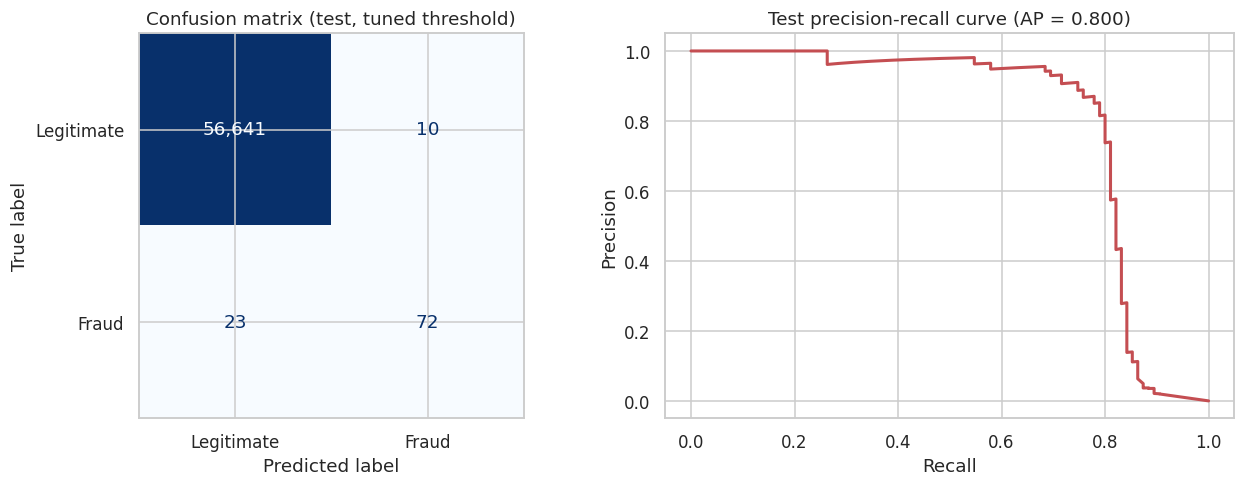

In [16]:
pred = (test_proba >= threshold).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Legitimate', 'Fraud']).plot(ax=axes[0], cmap='Blues', colorbar=False, values_format=',')
axes[0].set_title('Confusion matrix (test, tuned threshold)')
pr_t, rc_t, _ = precision_recall_curve(y_test, test_proba)
axes[1].plot(rc_t, pr_t, color='#C44E52', lw=2); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title(f'Test precision-recall curve (AP = {average_precision_score(y_test, test_proba):.3f})')
plt.tight_layout()
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f'Caught {tp} of {tp + fn} frauds ({tp / (tp + fn):.1%}); {fp} false alarms among {tn + fp:,} legitimate transactions ({fp / (tn + fp):.3%}).')

### Business view: what is it worth?

Metrics are abstract; money is not. Assumptions (edit them):
- a fraud that is **missed** costs the full transaction amount;
- every **alert** (true or false) costs **$5** of analyst/customer-contact time (`REVIEW_COST`, an assumption, not from the data).

The net benefit compares the model with doing nothing.

In [17]:
REVIEW_COST = 5.0   # assumed cost in $ of handling one alert
amt_test = amount[i_test]
caught_value = amt_test[(pred == 1) & (y_test == 1)].sum()
missed_value = amt_test[(pred == 0) & (y_test == 1)].sum()
alerts = int(pred.sum())
net = caught_value - REVIEW_COST * alerts
print(f'Total fraud value in test set : ${amt_test[y_test == 1].sum():>10,.0f}')
print(f'Fraud value caught            : ${caught_value:>10,.0f}')
print(f'Fraud value missed            : ${missed_value:>10,.0f}')
print(f'Alerts raised                 : {alerts:>10,}  -> review cost ${REVIEW_COST * alerts:,.0f}')
print(f'Net benefit vs doing nothing  : ${net:>10,.0f}')

Total fraud value in test set : $    14,766
Fraud value caught            : $    10,734
Fraud value missed            : $     4,032
Alerts raised                 :         82  -> review cost $410
Net benefit vs doing nothing  : $    10,324

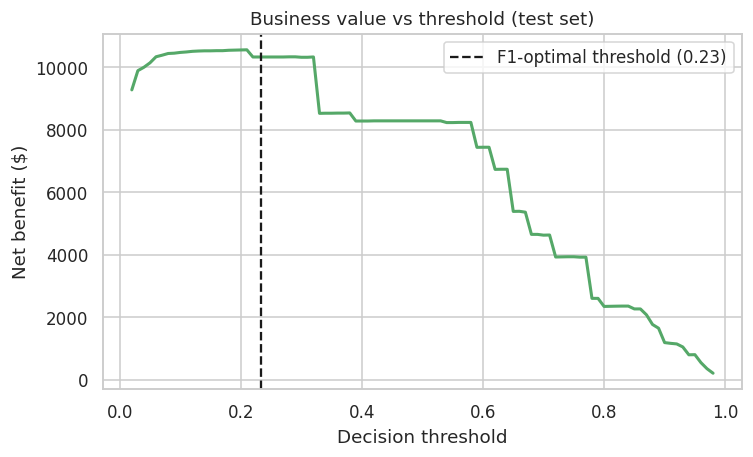

In [18]:
# Net benefit for different thresholds on the test set
ths = np.linspace(0.02, 0.98, 97)
benefit = []
for t in ths:
    p = test_proba >= t
    benefit.append(amt_test[p & (y_test == 1)].sum() - REVIEW_COST * p.sum())
plt.figure(figsize=(7.5, 4.2))
plt.plot(ths, benefit, color='#55A868', lw=2)
plt.axvline(threshold, color='k', ls='--', label=f'F1-optimal threshold ({threshold:.2f})')
plt.xlabel('Decision threshold'); plt.ylabel('Net benefit ($)'); plt.title('Business value vs threshold (test set)'); plt.legend()

## 7. What does the model look at?

     importance
V14       0.199
V10       0.120
V4        0.114
V17       0.093
V12       0.075
V3        0.074
V11       0.073
V16       0.032
V2        0.028
V7        0.026
V19       0.014
V9        0.013

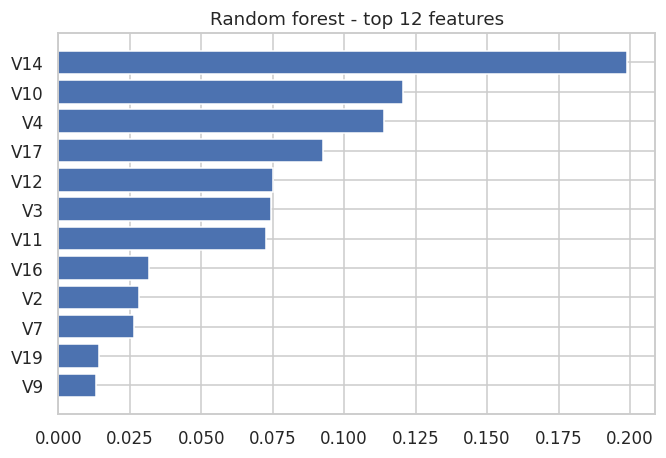

In [19]:
rf = fitted['Random Forest']
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False).head(12)
plt.figure(figsize=(7, 4.5))
plt.barh(imp.index[::-1], imp.values[::-1], color='#4C72B0'); plt.title('Random forest - top 12 features')
imp.round(3).to_frame('importance')

## 8. Save the model

In [20]:
joblib.dump({'model': best_model, 'threshold': threshold, 'features': feature_cols, 'name': best_name}, 'fraud_model.joblib')

def score_transactions(frame):
    """frame needs columns V1..V28, Amount and Time. Returns fraud probability and a flag."""
    f = frame.copy()
    f['Amount_log'] = np.log1p(f['Amount']); f['Hour'] = (f['Time'] // 3600) % 24
    proba = best_model.predict_proba(f[feature_cols].values)[:, 1]
    return pd.DataFrame({'fraud_probability': proba, 'flag_for_review': proba >= threshold}, index=frame.index)

sample = df.iloc[np.r_[np.where(df['Class'] == 1)[0][:3], np.where(df['Class'] == 0)[0][:3]]]
pd.concat([sample[['Time', 'Amount', 'Class']], score_transactions(sample)], axis=1).round(3)

        Time  Amount  Class  fraud_probability  flag_for_review
534    406.0    0.00      1              0.720             True
616    472.0  529.00      1              0.239             True
4886  4462.0  239.93      1              0.213            False
0        0.0  149.62      0              0.000            False
1        0.0    2.69      0              0.000            False
2        1.0  378.66      0              0.000            False

## 9. Conclusions

1. **Accuracy is meaningless here:** predicting "legitimate" every time scores 99.83% accuracy yet catches zero fraud. Precision, recall, F1 and PR-AUC tell the real story.
2. **Handling imbalance changes the trade-off, not the ranking ability.** Class weights, undersampling and SMOTE pushed logistic-regression recall from 68% to 89-92% but multiplied false alarms (8 -> 116-1,554 on validation). Their PR-AUC stayed close to 0.79-0.80, the same as the plain baseline.
3. **Non-linear tree models were clearly better:** Random Forest and Gradient Boosting reached a validation PR-AUC of about 0.86 against 0.80 for logistic regression, with both high precision and good recall.
4. **Final model (Random Forest, threshold about 0.23):** on the untouched test set it caught **72 of 95 frauds (76%)** with just **10 false alarms among 56,651 legitimate transactions** (precision 88%, F1 0.81).
5. **Business value:** under the stated assumptions (missed fraud costs its amount, each alert costs $5) the model recovers roughly **$10.7k of the $14.8k fraud value** in the test period for a net benefit of about $10.3k. The best operating threshold depends on these costs.
6. **Main drivers:** V14, V10, V4, V17 and V12 (anonymised, so their business meaning is unknown).

**Limitations and next steps**
- Only 473 frauds: all metrics have wide uncertainty (compare validation 0.86 with test 0.80 PR-AUC).
- The split is random, but real fraud detection must predict *future* transactions; validate with a time-based split and monitor for drift as fraud patterns change.
- Features are anonymised, which limits feature engineering and explanation; real systems add customer history, merchant and device information.
- Next steps: cross-validated tuning of the boosting model, probability calibration, cost-sensitive threshold selection with real costs, and an alert-review capacity limit.